# 01 – FLUID dataset: exploratory data analysis

**Project:** Real-Time Road Hazard Detection
**Dataset:** FLUID (Chen et al., 2025), CC BY 4.0 – https://doi.org/10.6084/m9.figshare.29974954

This notebook answers the questions we need settled before building the pipeline:

1. How much data is there (recordings, duration, frame rate)?
2. Which road users appear, and how many of each class?
3. Do trajectories contain **pixel** coordinates, **metric** coordinates, or both – and can we recover the pixel → world mapping (homography) ourselves?
4. How clean is the data (interpolated points, confidence, stationary objects, speed outliers, unknown directions)?
5. How do road users move through the intersection (turning movements, speeds, density)?
6. Which movements are signal-controlled, how long is the signal cycle, and how many vehicles enter on red?
7. Conflict annotations and signal timings (if the files are present).

All figures are saved to `results/eda/` for the report and poster.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = "/content/drive/MyDrive/MPVI projekat/Road-Hazard-Detection"  # prilagodite putanju
os.environ["FLUID_DIR"] = f"{PROJECT}/data/FLUID"
os.chdir(f"{PROJECT}/notebooks")

Mounted at /content/drive


In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.data.fluid import (
    VULNERABLE_CLASSES, apply_homography, find_files, fit_homography,
    green_intervals, load_conflicts, load_routes, load_signals, load_trajectories,
    phase_at, track_summary,
)

# Folder with the downloaded FLUID files (set FLUID_DIR or edit this line)
DATA_DIR = Path(os.environ.get("FLUID_DIR", ROOT / "data" / "FLUID"))
FIG_DIR = ROOT / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
print("Data folder:", DATA_DIR)

Data folder: /content/drive/MyDrive/MPVI projekat/Road-Hazard-Detection/data/FLUID


In [3]:
# Chart style: light surface, recessive axes, thin marks
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3
BLUE = SERIES[0]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.5, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

## 1. Files and recordings

In [4]:
import re

# Main trajectory files start with the recording date, e.g. 20250529_video-1_Traj.csv.
# Files with an intersection prefix (e.g. TI_20250529_video-1_Traj.csv) are a separate,
# smaller trajectory set and must not be loaded as extra recordings.
all_traj = find_files(DATA_DIR, "*_Traj.csv")
traj_files = [p for p in all_traj if re.match(r"^\d{8}_", p.name)]
ignored_traj = [p for p in all_traj if p not in traj_files]
conflict_files = [p for p in find_files(DATA_DIR, "*.csv") if "conflict" in p.name.lower()]
signal_files = [p for p in find_files(DATA_DIR, "*.csv") if "signal" in p.name.lower()]
route_files = [p for p in find_files(DATA_DIR, "*.csv") if "route" in p.name.lower()]
video_files = find_files(DATA_DIR, "*.mp4")

for label, files in [("Trajectories", traj_files), ("Conflicts", conflict_files),
                     ("Signals", signal_files), ("Routes", route_files), ("Videos", video_files)]:
    print(f"{label:<13} {len(files):>3} file(s)")
    for f in files:
        print("   ", f.relative_to(DATA_DIR))
if ignored_traj:
    print("\nIgnored (not main trajectory files):")
    for f in ignored_traj:
        print("   ", f.relative_to(DATA_DIR))

Trajectories    3 file(s)
    20250529_video-1_Traj.csv
    20250529_video-2_Traj.csv
    20250529_video-3_Traj.csv
Conflicts       1 file(s)
    TI_conflict.csv
Signals         3 file(s)
    20250529_video-1_signal.csv
    20250529_video-2_signal.csv
    20250529_video-3_signal.csv
Routes          3 file(s)
    20250529_video-1_Route.csv
    20250529_video-2_Route.csv
    20250529_video-3_Route.csv
Videos          0 file(s)

Ignored (not main trajectory files):
    TI_20250529_video-1_Traj.csv
    TI_20250529_video-2_Traj.csv
    TI_20250529_video-3_Traj.csv


In [5]:
traj = load_trajectories(traj_files)

recordings = traj.groupby("recording").agg(
    rows=("frame", "size"),
    frames=("frame", "max"),
    duration_min=("time", lambda t: t.max() / 60),
    tracks=("id", "nunique"),
    entry_legs=("entry_direction", lambda s: "".join(sorted(set(s) - {"Unknown"}))),
)
recordings["fps"] = traj.groupby("recording")["time"].apply(lambda t: 1 / np.median(np.diff(np.sort(t.unique()))))
recordings["intersection (inferred)"] = recordings["entry_legs"].map(
    lambda legs: "T-intersection (TI)" if len(legs) == 3 else "4-way (FI / FIDRT)")
recordings.round(1)

,rows,frames,duration_min,tracks,entry_legs,fps,intersection (inferred)
recording,,,,,,,
20250529_video-1,157356,16551,27.6,519,ENW,10.0,T-intersection (TI)
20250529_video-2,137615,15825,26.4,524,ENW,10.0,T-intersection (TI)
20250529_video-3,137734,14436,24.1,472,ENW,10.0,T-intersection (TI)


In [6]:
print(f"Total: {len(recordings)} recordings, {recordings.duration_min.sum():.1f} min, "
      f"{recordings.tracks.sum()} tracks, {len(traj):,} trajectory rows")

Total: 3 recordings, 78.0 min, 1515 tracks, 432,705 trajectory rows


**Note.** The intersection type is inferred from the approach legs found in `entry_direction`
(three legs → T-intersection). Recordings from the same date belong to the same intersection,
so the leave-one-intersection-out split needs files from **all three** FLUID intersections.

## 2. Columns

Meanings below are inferred from the column names and values and should be checked against the FLUID `README.md`.

| Column | Meaning | Unit |
|---|---|---|
| `frame`, `time` | frame index, time since start | –, s |
| `id` | track id (restarts in every recording) | – |
| `cx`, `cy`, `w`, `h`, `r` | oriented bounding box: centre, width, height, rotation | px, rad |
| `smooth_cx`, `smooth_cy`, `smooth_r` | smoothed box centre and rotation | px, rad |
| `confidence` | detector confidence (empty for interpolated points) | 0–1 |
| `type` | road-user class | – |
| `isReal` | 1 = detected, 0 = interpolated | – |
| `cx_m`, `cy_m` | position in the local metric coordinate system | m |
| `w_m`, `h_m`, `length_med`, `width_med` | object size, per frame and per-track median | m |
| `speed`, `speed_smooth`, `vx`, `vy` | raw and smoothed speed, velocity components | m/s |
| `ax`, `ay` | acceleration components | m/s² |
| `course`, `yaw` | direction of motion, vehicle orientation | rad |
| `entry_direction`, `exit_direction`, `overall_direction` | approach leg, exit leg, movement | – |

In [7]:
traj.head()

,frame,id,cx,cy,w,h,r,confidence,type,w_m,h_m,time,speed,cx_m,cy_m,smooth_cx,smooth_cy,smooth_r,r_align,isReal,length_med,width_med,w_med,h_med,course,yaw,speed_smooth,vx,vy,ax,ay,entry_direction,exit_direction,overall_direction,recording,track_uid,group
0,1,4,1300.87,899.91,64.19,35.89,3.0084,0.81,moped,2.71,1.51,0.1,0.00,21.78,4.09,1300.33,899.95,3.0096,6.0143,1,2.51,1.24,59.53,29.44,NaN,2.8794,1.98,-1.91,0.51,-5.12,1.37,E,W,E-W,20250529_video-1,20250529_video-1/4,two/three-wheeler
1,2,4,1303.00,898.91,64.24,34.76,3.0154,0.77,moped,2.71,1.47,0.2,1.26,21.66,4.11,1303.14,899.14,3.0056,6.0183,1,2.51,1.24,59.53,29.44,2.9764,2.8794,2.51,-2.42,0.65,-5.07,1.36,E,W,E-W,20250529_video-1,20250529_video-1/4,two/three-wheeler
2,3,4,1307.69,898.97,63.86,34.17,2.9886,0.76,moped,2.69,1.44,0.3,2.82,21.39,4.20,1309.83,898.37,3.0029,6.0210,1,2.51,1.24,59.53,29.44,2.8198,2.8794,3.03,-2.93,0.79,-4.93,1.32,E,W,E-W,20250529_video-1,20250529_video-1/4,two/three-wheeler
3,4,4,1320.50,897.62,64.09,34.85,2.9883,0.80,moped,2.70,1.47,0.4,4.14,21.00,4.33,1319.60,897.59,2.9996,6.0244,1,2.51,1.24,59.53,29.44,2.8198,2.8828,3.53,-3.41,0.90,-4.64,1.23,E,W,E-W,20250529_video-1,20250529_video-1/4,two/three-wheeler
4,5,4,1333.74,896.24,60.63,32.98,3.0210,0.76,moped,2.56,1.39,0.5,5.09,20.52,4.50,1331.64,896.76,2.9934,6.0305,1,2.51,1.24,59.53,29.44,2.8012,2.8889,3.99,-3.86,1.00,-4.21,1.09,E,W,E-W,20250529_video-1,20250529_video-1/4,two/three-wheeler


## 3. Road users by class

In [8]:
tracks = track_summary(traj)

class_counts = tracks["type"].value_counts()
class_table = pd.DataFrame({"tracks": class_counts, "share_%": (100 * class_counts / class_counts.sum()).round(1)})
class_table["vulnerable"] = class_table.index.isin(VULNERABLE_CLASSES)
display(class_table)

vru_share = 100 * tracks["type"].isin(VULNERABLE_CLASSES).mean()
print(f"Vulnerable road users (pedestrian, moped, tricycle): {vru_share:.1f}% of tracks")

,tracks,share_%,vulnerable
type,,,
car,1106,73.0,False
moped,192,12.7,True
truck,134,8.8,False
pedestrian,41,2.7,True
trailer,17,1.1,False
bus,13,0.9,False
tricycle,6,0.4,True
van,6,0.4,False


Vulnerable road users (pedestrian, moped, tricycle): 15.8% of tracks


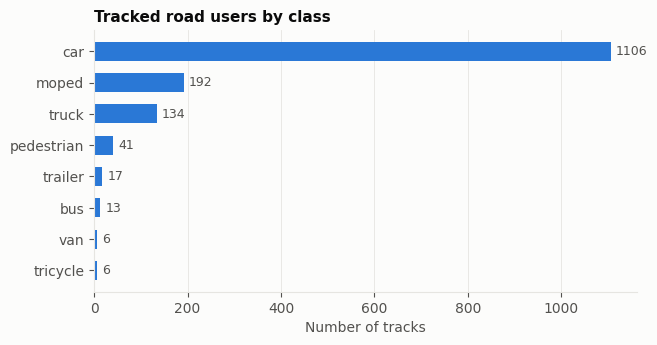

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ordered = class_counts.sort_values()
ax.barh(ordered.index, ordered.values, color=BLUE, height=0.6)
for y, v in enumerate(ordered.values):
    ax.text(v + ordered.max() * 0.01, y, f"{v}", va="center", color=INK_2, fontsize=9)
ax.set_title("Tracked road users by class")
ax.set_xlabel("Number of tracks")
ax.grid(axis="y", visible=False)
save(fig, "01_classes")
plt.show()

**Class imbalance.** Cars dominate; pedestrians, buses, vans and tricycles are rare.
This matters for detector training (rare classes need oversampling, class weights, or an extra dataset such as VisDrone)
and for the conflict-prediction model (conflicts are rare events compared to normal driving).

## 4. Pixel vs. metric coordinates

Each row contains both pixel coordinates (`cx`, `cy`, `smooth_cx`, `smooth_cy`) and metric coordinates (`cx_m`, `cy_m`).
If the drone camera is stable, one homography should map pixels to metres for the whole recording.
We fit it from the data (normalised DLT) and measure the reprojection error.
This is exactly the transformation our own pipeline will need in layer 1: YOLO gives pixels, TTC/PET need metres.

In [10]:
rows = []
homographies = {}
for rec, df in traj[traj["isReal"] == 1].groupby("recording"):
    world = df[["cx_m", "cy_m"]].to_numpy()
    for px_cols in [("cx", "cy"), ("smooth_cx", "smooth_cy")]:
        px = df[list(px_cols)].to_numpy()
        H = fit_homography(px, world)
        err = np.linalg.norm(apply_homography(H, px) - world, axis=1)
        rows.append({"recording": rec, "pixels": px_cols[0], "mean_err_m": err.mean(),
                     "median_err_m": np.median(err), "p95_err_m": np.percentile(err, 95), "max_err_m": err.max()})
        if px_cols[0] == "smooth_cx":
            homographies[rec] = H

homography_errors = pd.DataFrame(rows)
homography_errors.round(3)

,recording,pixels,mean_err_m,median_err_m,p95_err_m,max_err_m
0,20250529_video-1,cx,0.046,0.028,0.126,6.658
1,20250529_video-1,smooth_cx,0.005,0.005,0.010,0.014
2,20250529_video-2,cx,0.047,0.027,0.133,6.935
3,20250529_video-2,smooth_cx,0.005,0.005,0.010,0.014
4,20250529_video-3,cx,0.043,0.025,0.125,8.492
5,20250529_video-3,smooth_cx,0.005,0.005,0.010,0.014


In [11]:
scale = (traj["w_m"] / traj["w"]).median()
print(f"Ground resolution: ~{100 * scale:.1f} cm per pixel")
for rec, H in homographies.items():
    print(f"\nHomography (smoothed pixels -> metres), {rec}:\n{np.array2string(H, precision=6, suppress_small=True)}")

Ground resolution: ~4.2 cm per pixel

Homography (smoothed pixels -> metres), 20250529_video-1:
[[ -0.038663   0.016522  57.127131]
 [  0.016453   0.038495 -51.949957]
 [ -0.000003   0.000002   1.      ]]

Homography (smoothed pixels -> metres), 20250529_video-2:
[[ -0.03852    0.021971  55.578516]
 [  0.020266   0.037183 -68.367647]
 [  0.000023  -0.000028   1.      ]]

Homography (smoothed pixels -> metres), 20250529_video-3:
[[ -0.039324   0.020132  54.654688]
 [  0.018338   0.037757 -60.314648]
 [  0.00002   -0.000026   1.      ]]


**Result.** Both coordinate systems are present. Smoothed pixel coordinates map to metres with a single homography
at **millimetre-level error**, so the metric coordinates are a projective transform of the smoothed pixels.
Raw detection centres (`cx`, `cy`) deviate by a few centimetres on average because they are not smoothed.

Consequences for the project:
- Our YOLO detections (pixels) can be converted to metres with this homography and compared directly with FLUID trajectories.
- The matrix **differs between recordings** of the same intersection (the drone hovers at a slightly different position each flight), so a separate homography is needed per recording (or per video, for our own footage).

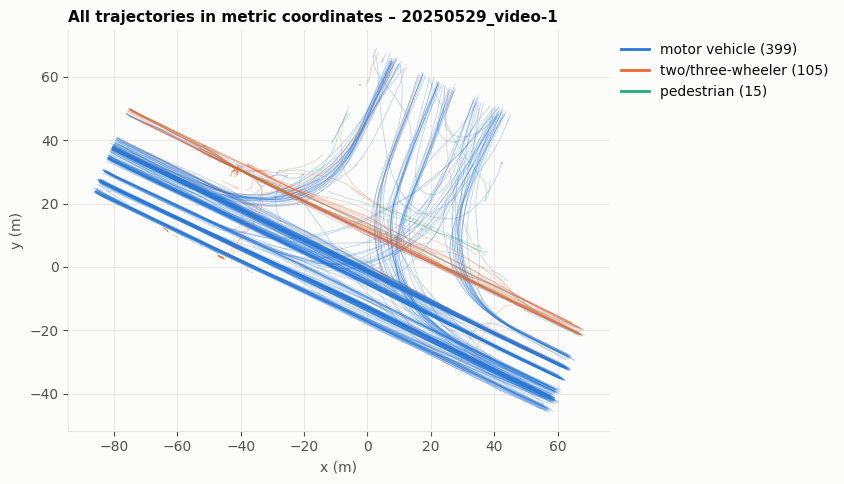

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sample_rec = traj["recording"].iloc[0]
d = traj[traj["recording"] == sample_rec]
for group, color in zip(["motor vehicle", "two/three-wheeler", "pedestrian"], SERIES):
    g = d[d["group"] == group]
    for _, t in g.groupby("id"):
        ax.plot(t["cx_m"], t["cy_m"], color=color, linewidth=0.5, alpha=0.35)
    ax.plot([], [], color=color, linewidth=2, label=f"{group} ({g['id'].nunique()})")
ax.set_aspect("equal")
ax.set_title(f"All trajectories in metric coordinates – {sample_rec}")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "02_trajectories_map")
plt.show()

## 5. Data quality

In [13]:
quality = traj.groupby("recording").agg(
    interpolated_pct=("isReal", lambda s: 100 * (1 - s.mean())),
    mean_confidence=("confidence", "mean"),
    raw_speed_max=("speed", "max"),
    smooth_speed_max=("speed_smooth", "max"),
)
quality["tracks"] = tracks.groupby("recording").size()
quality["stationary_tracks"] = tracks[tracks["displacement_m"] < 5].groupby("recording").size()
quality["unknown_direction_tracks"] = tracks[(tracks["entry"] == "Unknown") | (tracks["exit"] == "Unknown")].groupby("recording").size()
quality["tracks_over_20_mps"] = tracks[tracks["max_speed_smooth"] > 20].groupby("recording").size()
quality.fillna(0).round(2)

,interpolated_pct,mean_confidence,raw_speed_max,smooth_speed_max,tracks,stationary_tracks,unknown_direction_tracks,tracks_over_20_mps
recording,,,,,,,,
20250529_video-1,3.57,0.77,60.19,22.88,519,51,46,14
20250529_video-2,1.54,0.82,88.64,29.44,524,31,27,20
20250529_video-3,1.14,0.82,117.97,38.94,472,30,24,18


In [14]:
print("Missing values (columns with any):")
print(traj.isna().sum()[lambda s: s > 0].to_string())
print("\nMissing pixel boxes only on interpolated rows:",
      traj.loc[traj["cx"].isna(), "isReal"].eq(0).all())
print("Tracks that change class:", int((traj.groupby("track_uid")["type"].nunique() > 1).sum()))
print("Frame gaps inside tracks:", int(traj.sort_values("frame").groupby("track_uid")["frame"].apply(lambda f: (np.diff(f) > 1).sum()).sum()))

Missing values (columns with any):
cx            9310
cy            9310
r             9310
confidence    9310
course        1515

Missing pixel boxes only on interpolated rows: True
Tracks that change class: 0
Frame gaps inside tracks: 0


In [16]:
stationary = tracks[tracks["displacement_m"] < 5]
print(f"Stationary tracks (displacement < 5 m): {len(stationary)}")
print(stationary["type"].value_counts().to_string())

Stationary tracks (displacement < 5 m): 112
type
moped         74
pedestrian    26
car            8
truck          4


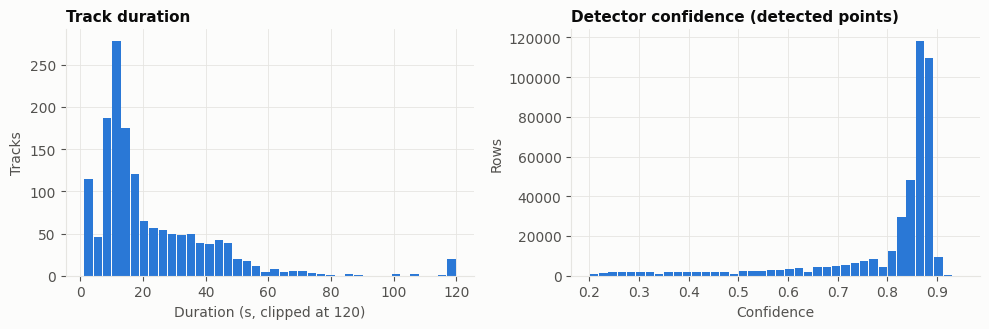

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

ax = axes[0]
ax.hist(tracks["duration_s"].clip(upper=120), bins=40, color=BLUE, rwidth=0.9)
ax.set_title("Track duration")
ax.set_xlabel("Duration (s, clipped at 120)")
ax.set_ylabel("Tracks")

ax = axes[1]
ax.hist(traj["confidence"].dropna(), bins=40, color=BLUE, rwidth=0.9)
ax.set_title("Detector confidence (detected points)")
ax.set_xlabel("Confidence")
ax.set_ylabel("Rows")
fig.tight_layout()
save(fig, "03_duration_confidence")
plt.show()

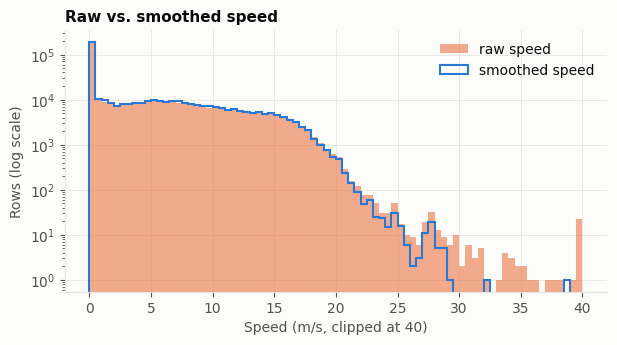

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 40, 81)
ax.hist(traj["speed"].clip(upper=40), bins=bins, color=SERIES[1], alpha=0.55, label="raw speed")
ax.hist(traj["speed_smooth"].clip(lower=0, upper=40), bins=bins, histtype="step", color=SERIES[0], linewidth=1.5, label="smoothed speed")
ax.set_yscale("log")
ax.set_title("Raw vs. smoothed speed")
ax.set_xlabel("Speed (m/s, clipped at 40)")
ax.set_ylabel("Rows (log scale)")
ax.legend(frameon=False)
save(fig, "04_speed_raw_vs_smooth")
plt.show()

**Findings to handle during cleaning**

- **Interpolated points** (`isReal = 0`): have no pixel box or confidence. Keep them for trajectory analysis, exclude them when evaluating detection.
- **Stationary objects** (net displacement < 5 m): mostly parked mopeds, some lasting the whole recording. Parked vehicles should be filtered before conflict analysis. **Pedestrians must not be filtered this way**: many of them wait at the kerb or walk short distances, and they are exactly the road users we care about.
- **Speed outliers**: raw speed has physically impossible spikes (detection jitter); use `speed_smooth`. A few smoothed values above 20 m/s (72 km/h) in an urban intersection should still be inspected.
- **Unknown directions**: tracks that start or end inside the scene; they cannot be assigned a turning movement.
- **Speeds above 20 m/s** (72 km/h) appear in a few tracks even after smoothing (max ≈ 39 m/s ≈ 140 km/h); these are almost certainly tracking errors and should be inspected or capped.
- No class changes and no frame gaps inside tracks (gaps were already filled by interpolation).

## 6. Movement patterns

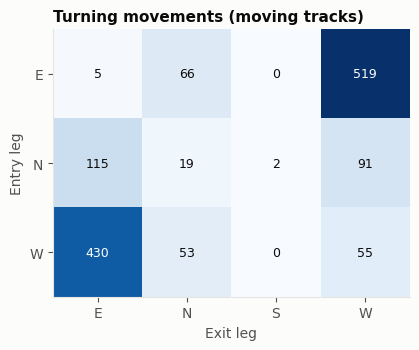

In [19]:
moving = tracks[(tracks["displacement_m"] >= 5) & (tracks["entry"] != "Unknown") & (tracks["exit"] != "Unknown")]
od = pd.crosstab(moving["entry"], moving["exit"])

fig, ax = plt.subplots(figsize=(4.6, 3.6))
im = ax.imshow(od.values, cmap="Blues")
ax.set_xticks(range(len(od.columns)), od.columns)
ax.set_yticks(range(len(od.index)), od.index)
ax.set_xlabel("Exit leg")
ax.set_ylabel("Entry leg")
ax.grid(False)
for i in range(od.shape[0]):
    for j in range(od.shape[1]):
        v = od.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > od.values.max() * 0.55 else INK)
ax.set_title("Turning movements (moving tracks)")
save(fig, "05_turning_movements")
plt.show()

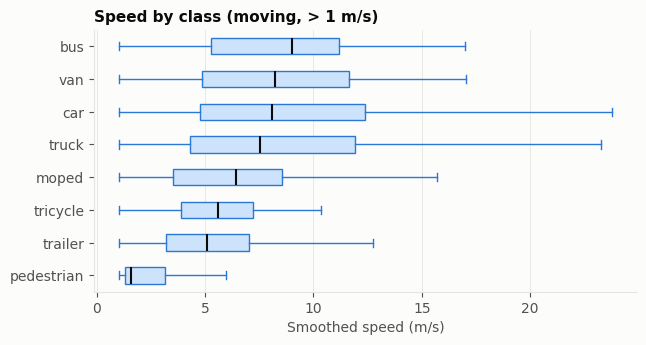

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.4))
moving_rows = traj[traj["speed_smooth"] > 1]
order = moving_rows.groupby("type")["speed_smooth"].median().sort_values().index
data = [moving_rows.loc[moving_rows["type"] == t, "speed_smooth"].clip(lower=0) for t in order]
import matplotlib
horizontal = {"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}
bp = ax.boxplot(data, tick_labels=order, showfliers=False, widths=0.5, patch_artist=True, **horizontal)
for box in bp["boxes"]:
    box.set(facecolor="#cde2fb", edgecolor=BLUE, linewidth=1)
for part in ["whiskers", "caps"]:
    for line in bp[part]:
        line.set(color=BLUE, linewidth=1)
for line in bp["medians"]:
    line.set(color=INK, linewidth=1.5)
ax.set_title("Speed by class (moving, > 1 m/s)")
ax.set_xlabel("Smoothed speed (m/s)")
ax.grid(axis="y", visible=False)
save(fig, "06_speed_by_class")
plt.show()

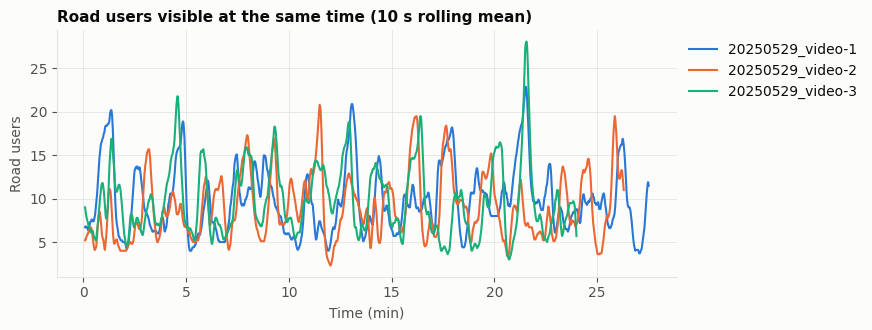

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for (rec, d), color in zip(traj.groupby("recording"), SERIES * 4):
    per_second = d.groupby(d["time"].round())["id"].nunique()
    ax.plot(per_second.index / 60, per_second.rolling(10, center=True).mean(), color=color, label=rec)
ax.set_title("Road users visible at the same time (10 s rolling mean)")
ax.set_xlabel("Time (min)")
ax.set_ylabel("Road users")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "07_density_over_time")
plt.show()

**Observations.** Through traffic (E→W, W→E) dominates; same-leg movements (W→W, E→E) are most likely U-turns.
Two-wheelers use their own lane, separate from motor vehicles. The number of road users rises and falls in regular waves,
most likely following the traffic-signal cycle – this will be checked against the signal timings in layer 2.

## 7. Routes and signal states

`*_Route.csv` has one row per **motor-vehicle** track (mopeds and pedestrians are not included) with the turning movement
and the signal state when the vehicle crossed into and out of the intersection.
Codes are inferred from the data: `turn` – s straight, l left, r right, t U-turn; `in_state` / `out_state` – G green, y yellow, r red;
`in_cycle` – signal cycle number; `in_delta` – seconds since the current signal state began; `in_time` / `out_time` – entry and exit time (s).

In [22]:
routes = load_routes(route_files)
print(f"{len(routes)} motor-vehicle routes in {routes['recording'].nunique()} recordings")
print("Classes missing from routes:", sorted(set(tracks['type']) - set(routes['type'])))

movement = pd.crosstab(routes["turn_name"].fillna("unknown"), routes["entry_signal"].fillna("no signal state"))
movement

1282 motor-vehicle routes in 3 recordings
Classes missing from routes: ['moped', 'pedestrian']


entry_signal,green,no signal state,red,yellow
turn_name,,,,
U-turn,0,58,0,0
left,130,2,30,4
right,0,149,0,0
straight,812,3,50,19
unknown,0,25,0,0


Right turns and U-turns have **no signal state** – they are not controlled by the traffic light (permissive movements).
These are exactly the places where conflicts with pedestrians and through traffic are expected.

In [23]:
controlled = routes[routes["entry_signal"].notna()]

cycle_start = controlled.groupby(["recording", "in_cycle"])["in_time"].min()
cycle_length = cycle_start.groupby(level=0).diff().groupby(level=0).median()

signal_summary = pd.DataFrame({
    "cycles": controlled.groupby("recording")["in_cycle"].nunique(),
    "median_cycle_s": cycle_length.round(1),
    "controlled_vehicles": controlled.groupby("recording").size(),
    "entered_on_yellow": controlled[controlled["entry_signal"] == "yellow"].groupby("recording").size(),
    "entered_on_red": controlled[controlled["entry_signal"] == "red"].groupby("recording").size(),
}).fillna(0)
signal_summary["red_%"] = (100 * signal_summary["entered_on_red"] / signal_summary["controlled_vehicles"]).round(1)
signal_summary

,cycles,median_cycle_s,controlled_vehicles,entered_on_yellow,entered_on_red,red_%
recording,,,,,,
20250529_video-1,24,70.8,325,6,7,2.2
20250529_video-2,23,71.1,370,6,14,3.8
20250529_video-3,21,71.6,350,11,59,16.9


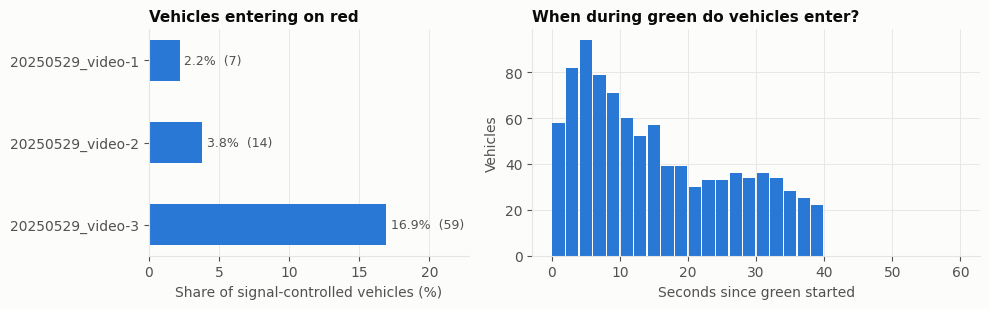

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
red = signal_summary["red_%"]
ax.barh(red.index, red.values, color=BLUE, height=0.5)
for y, (v, n) in enumerate(zip(red.values, signal_summary["entered_on_red"])):
    ax.text(v + red.max() * 0.02, y, f"{v:.1f}%  ({int(n)})", va="center", color=INK_2, fontsize=9)
ax.set_title("Vehicles entering on red")
ax.set_xlabel("Share of signal-controlled vehicles (%)")
ax.set_xlim(0, red.max() * 1.35)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)

ax = axes[1]
green = controlled[controlled["entry_signal"] == "green"]
ax.hist(green["in_delta"].clip(upper=60), bins=np.arange(0, 61, 2), color=BLUE, rwidth=0.9)
ax.set_title("When during green do vehicles enter?")
ax.set_xlabel("Seconds since green started")
ax.set_ylabel("Vehicles")
fig.tight_layout()
save(fig, "08_signal_entry")
plt.show()

**Findings**

- The signal cycle is about **70 s**, which matches the regular waves in the road-user density plot.
- Green lasts about **40 s** (no vehicle enters later than ~40 s into green). Most vehicles enter in the first seconds of green (queue discharge). Whether conflicts follow the same pattern is checked in section 8.
- Red-light entries differ strongly between recordings. A much higher rate in one recording may be real behaviour or a signal-timing synchronisation problem; it has to be checked against the signal files and the video before red-light running is used as a feature.

## 8. Conflicts and signal timings

FLUID provides one conflict file per intersection and one signal-timing file per recording.

In [25]:
conflicts = load_conflicts(conflict_files)
signals = load_signals(signal_files)

per_rec = conflicts.groupby("recording").size().rename("conflicts").to_frame()
per_rec["minutes"] = recordings["duration_min"]
per_rec["conflicts_per_hour"] = (60 * per_rec["conflicts"] / per_rec["minutes"]).round(1)
display(per_rec)
print(f"Total: {len(conflicts)} conflicts in {per_rec['minutes'].sum():.0f} min "
      f"({60 * len(conflicts) / per_rec['minutes'].sum():.0f} per hour)")

known_ids = set(traj["track_uid"])
missing = sum((conflicts["recording"] + "/" + conflicts[col].astype(str)).isin(known_ids).eq(False).sum() for col in ["id_1", "id_2"])
print("Conflict track ids not found in the trajectory files:", missing)

,conflicts,minutes,conflicts_per_hour
recording,,,
20250529_video-1,22,27.585,47.9
20250529_video-2,34,26.375,77.3
20250529_video-3,13,24.060,32.4


Total: 69 conflicts in 78 min (53 per hour)
Conflict track ids not found in the trajectory files: 4


In [26]:
type_table = conflicts["conflict_type"].value_counts().rename("conflicts").to_frame()
type_table["share_%"] = (100 * type_table["conflicts"] / len(conflicts)).round(1)
display(type_table)
conflicts[["ttc", "dgt", "angle_diff_deg"]].describe().round(2)

,conflicts,share_%
conflict_type,,
rear end,53,76.8
head on,9,13.0
angle,4,5.8
sideswipe,3,4.3


,ttc,dgt,angle_diff_deg
count,69.00,69.00,69.00
mean,0.59,0.79,28.49
std,0.75,1.23,56.68
min,0.00,0.00,0.01
25%,0.02,0.00,0.73
50%,0.09,0.00,2.05
75%,1.26,1.60,8.73
max,2.00,4.00,177.60


**Important: all annotated conflicts are vehicle–vehicle.** FLUID's conflict analysis is restricted to motor vehicles,
so there is **no ground truth for pedestrian–vehicle conflicts**. Our pipeline can be validated on vehicle–vehicle conflicts;
pedestrian conflicts computed with the same method must be checked manually on a sample.

In [27]:
movement = (tracks.reset_index().set_index("track_uid")["recording"].to_frame()
            .join(traj.drop_duplicates("track_uid").set_index("track_uid")[["type", "overall_direction"]])
            .join(routes.set_index("track_uid")["turn_name"]))
movement["movement"] = movement["overall_direction"] + " " + movement["turn_name"].fillna("")

def describe(rec, track_id):
    key = f"{rec}/{track_id}"
    return movement["movement"].get(key, "unknown").strip()

pairs = conflicts.assign(
    m1=[describe(r, i) for r, i in zip(conflicts["recording"], conflicts["id_1"])],
    m2=[describe(r, i) for r, i in zip(conflicts["recording"], conflicts["id_2"])],
)
pairs["pair"] = [" × ".join(sorted([a, b])) for a, b in zip(pairs["m1"], pairs["m2"])]
pairs.groupby(["conflict_type", "pair"]).size().rename("conflicts").sort_values(ascending=False).head(15).to_frame()

conflicts
conflict_type pair                                  
rear end      E-W straight × E-W straight         20
              W-E straight × W-E straight         11
              W-E straight × W-N left              6
head on       E-W straight × W-W U-turn            5
rear end      W-E straight × unknown               3
head on       N-Unknown × W-N left                 2
rear end      N-W right × W-W U-turn               2
              W-N left × W-N left                  2
              N-W right × N-W right                2
sideswipe     W-E straight × W-E straight          2
head on       E-W straight × W-N left              1
              E-W straight × W-Unknown             1
angle         N-W right × W-W U-turn               1
              E-W straight × W-W U-turn            1
              W-E straight × W-E straight          1

**Who is involved.** Most conflicts are rear-end conflicts between vehicles in the same through movement (E→W, W→E).
Most **head-on** conflicts involve a **U-turn from the west leg (W→W)** meeting through traffic from the east (E→W);
the rest are left turns from the west (W→N) crossing opposing traffic. U-turns are not signal-controlled (section 7),
which makes them a natural target for a safety recommendation.

### Signal plan

In [28]:
plan = (signals.groupby(["direction", "turn", "state"])["duration"].median()
        .unstack("state").rename(columns={"G": "green_s", "y": "yellow_s", "r": "red_s"}))
plan.index = [f"{d} {dict(s='straight', l='left', p='pedestrian crossing')[t]}" for d, t in plan.index]
plan

state,green_s,red_s,yellow_s
E pedestrian crossing,25.0,46.0,NaN
E straight,40.0,28.0,3.0
N left,25.0,43.0,3.0
N pedestrian crossing,40.0,31.0,NaN
N straight,25.0,43.0,3.0
W left,40.0,28.0,3.0
W pedestrian crossing,25.0,46.0,NaN
W straight,40.0,28.0,3.0


The plan has **two phases** in a ~71 s cycle:

- **Phase A** (40 s green + 3 s yellow): straight from east and west, **left from west**, pedestrian crossing on the north leg.
- **Phase B** (25 s green + 3 s yellow): left and straight from north, pedestrian crossings on the east and west legs.

The west left turn runs **at the same time as the opposing east through movement** (a permissive left turn), which explains the left-turn head-on conflicts.

In [29]:
quality_rows = []
for rec, s in signals.groupby("recording"):
    a = green_intervals(s, "E", "s").assign(phase="A")
    b = green_intervals(s, "N", "s").assign(phase="B")
    seq = pd.concat([a, b]).sort_values("begin_time")
    repeated = seq["phase"].eq(seq["phase"].shift()) & seq["phase"].eq("A")
    raw_rows = len(pd.read_csv([f for f in signal_files if rec in f.name][0]))
    quality_rows.append({"recording": rec, "duplicate_rows_removed": raw_rows - len(s),
                         "skipped_phase_B_at_s": seq.loc[repeated, "begin_time"].tolist()})
pd.DataFrame(quality_rows).set_index("recording")

,duplicate_rows_removed,skipped_phase_B_at_s
recording,,
20250529_video-1,23,[]
20250529_video-2,22,[820]
20250529_video-3,19,"[120, 1327]"


**Signal file quality:** a few rows are exact duplicates (removed while loading), and in some cycles phase B is
**skipped** (phase A runs twice in a row, red for the north leg lasts ~115 s). This may be real (e.g. no demand from the north)
or an annotation error, and should be checked on the video.

### Conflicts by signal phase

In [30]:
phase_rows = []
for rec, c in conflicts.groupby("recording"):
    s = signals[signals["recording"] == rec]
    phases = {"phase A": green_intervals(s, "E", "s"), "phase B": green_intervals(s, "N", "s")}
    for t in c["time"]:
        name, since = phase_at(t, phases)
        phase_rows.append({"recording": rec, "phase": name, "seconds_into_green": since})
conflict_phase = pd.DataFrame(phase_rows)

green_minutes = {
    name: sum((green_intervals(signals[signals["recording"] == rec], d, "s")
               .eval("end_time - begin_time").sum()) for rec in signals["recording"].unique()) / 60
    for name, d in [("phase A", "E"), ("phase B", "N")]
}
by_phase = conflict_phase["phase"].value_counts().rename("conflicts").to_frame()
by_phase["green_minutes"] = by_phase.index.map(green_minutes)
by_phase["conflicts_per_green_minute"] = (by_phase["conflicts"] / by_phase["green_minutes"]).round(2)
by_phase

,conflicts,green_minutes,conflicts_per_green_minute
phase,,,
phase A,49,44.450000,1.10
phase B,18,26.633333,0.68
yellow / all-red,2,NaN,NaN


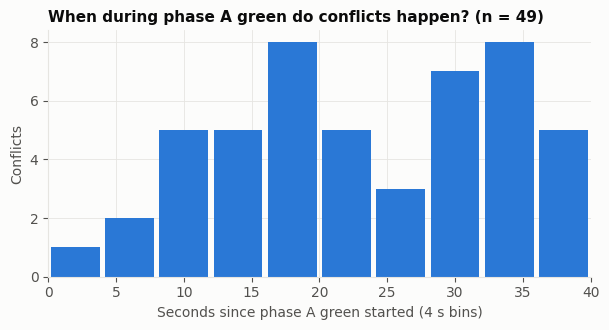

In [31]:
fig, ax = plt.subplots(figsize=(7, 3.2))
a = conflict_phase.loc[conflict_phase["phase"] == "phase A", "seconds_into_green"]
ax.hist(a, bins=np.arange(0, 41, 4), color=BLUE, rwidth=0.9)
ax.set_title(f"When during phase A green do conflicts happen? (n = {len(a)})")
ax.set_xlabel("Seconds since phase A green started (4 s bins)")
ax.set_ylabel("Conflicts")
ax.set_xlim(0, 40)
save(fig, "09_conflicts_in_phase")
plt.show()

Phase A has more conflicts both in total and per minute of green: it carries the heavy east–west through traffic and the permissive west left turn.
Although most vehicles enter in the first seconds of green (section 7), conflicts are **not** concentrated there: they are spread across the whole phase,
with few in the first 8 s. With only 49 conflicts the within-phase timing is noisy; the pattern has to be confirmed on the other intersections.

### Red-light entries: real violations or signal desynchronisation?

Section 7 showed many more red-light entries in one recording. Real red-light running is usually one vehicle at a time.
If **many vehicles enter "on red" within a few seconds**, a whole platoon is moving, which points to a signal-timing offset in the annotation.

In [32]:
red = routes[routes["entry_signal"] == "red"].sort_values(["recording", "in_time"])
red["burst"] = red.groupby("recording")["in_time"].diff().gt(15).groupby(red["recording"]).cumsum()
bursts = red.groupby(["recording", "burst"]).agg(start_s=("in_time", "min"), end_s=("in_time", "max"), vehicles=("id", "size"))
bursts["suspicious"] = bursts["vehicles"] >= 5
summary = bursts.groupby("recording").agg(red_entries=("vehicles", "sum"),
                                          in_suspicious_bursts=("vehicles", lambda v: v[bursts.loc[v.index, "suspicious"]].sum()))
display(summary)
bursts[bursts["suspicious"]].round(0)

,red_entries,in_suspicious_bursts
recording,,
20250529_video-1,7,0
20250529_video-2,14,0
20250529_video-3,59,53


start_s   end_s  vehicles  suspicious
recording        burst                                       
20250529_video-3 1         95.0   106.0         7        True
                 4       1086.0  1115.0        13        True
                 5       1163.0  1174.0         8        True
                 7       1301.0  1340.0        11        True
                 8       1373.0  1390.0        14        True

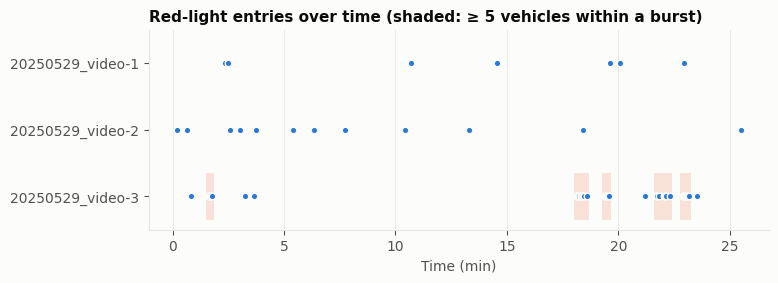

In [33]:
fig, ax = plt.subplots(figsize=(8, 2.6))
recs = sorted(routes["recording"].unique())
for y, rec in enumerate(recs):
    t = red.loc[red["recording"] == rec, "in_time"] / 60
    ax.scatter(t, np.full(len(t), y), s=22, color=BLUE, edgecolor=SURFACE, linewidth=1, zorder=3)
    for _, b in bursts.loc[rec].query("suspicious").iterrows():
        x0, x1 = b["start_s"] / 60 - 0.1, b["end_s"] / 60 + 0.1
        ax.add_patch(plt.Rectangle((x0, y - 0.35), x1 - x0, 0.7, color="#eb6834", alpha=0.18, linewidth=0, zorder=1))
ax.set_yticks(range(len(recs)), recs)
ax.set_ylim(-0.5, len(recs) - 0.5)
ax.invert_yaxis()
ax.set_xlabel("Time (min)")
ax.set_title("Red-light entries over time (shaded: ≥ 5 vehicles within a burst)")
ax.grid(axis="y", visible=False)
save(fig, "10_red_light_bursts")
plt.show()

In the recordings with few red entries, they are spread out in time (plausible individual violations).
In the recording with many, most of them fall into short bursts of 5–14 vehicles: the signal annotation there is most likely **offset in time** in those windows.
Red-light running should not be used as a model feature for those windows until the timing is verified on the video.

### Where do conflicts happen?

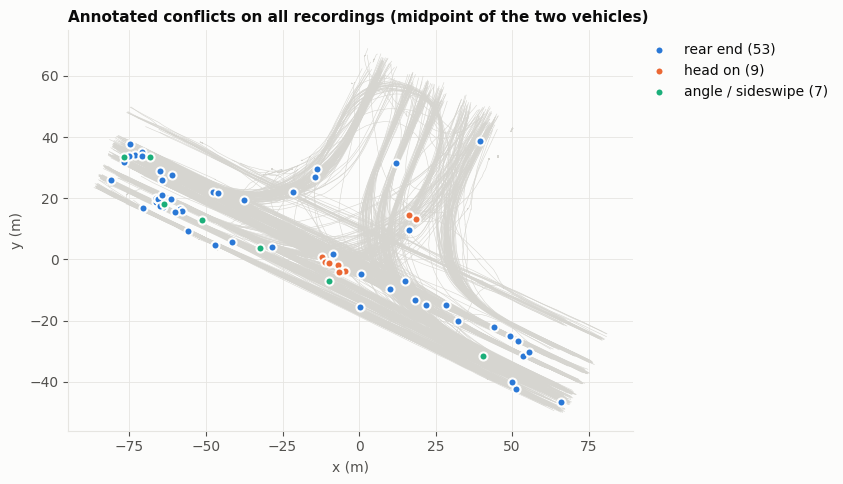

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for _, t in traj[traj["group"] == "motor vehicle"].groupby("track_uid"):
    ax.plot(t["cx_m"].iloc[::5], t["cy_m"].iloc[::5], color="#d6d5d0", linewidth=0.4, zorder=1)

groups = {"rear end": ["rear end"], "head on": ["head on"], "angle / sideswipe": ["angle", "sideswipe"]}
for (label, types), color in zip(groups.items(), SERIES):
    c = conflicts[conflicts["conflict_type"].isin(types)]
    x, y = (c["x_1"] + c["x_2"]) / 2, (c["y_1"] + c["y_2"]) / 2
    ax.scatter(x, y, s=34, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3, label=f"{label} ({len(c)})")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Annotated conflicts on all recordings (midpoint of the two vehicles)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "11_conflict_map")
plt.show()

Rear-end conflicts sit on the approaches, where queues form and discharge; head-on conflicts cluster in the centre of the intersection,
where west-leg U-turns and left turns cross the opposing through traffic.

In [36]:
if video_files:
    try:
        import cv2
        for v in video_files:
            cap = cv2.VideoCapture(str(v))
            n, fps = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
            w, h = cap.get(cv2.CAP_PROP_FRAME_WIDTH), cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
            print(f"{v.name}: {int(n)} frames, {fps:.2f} FPS, {n / fps / 60:.1f} min, {int(w)}x{int(h)}")
            cap.release()
    except ImportError:
        print("Install opencv-python to inspect the videos.")
else:
    print("No videos found in DATA_DIR.")

No videos found in DATA_DIR.


## 9. Summary

**Data**
- 3 recordings (78 min, 1,515 tracks, 10 FPS) from **one T-intersection**; the other two FLUID intersections are needed for a leave-one-intersection-out split.
- Trajectories contain **both pixel and metric coordinates**; one homography per recording maps smoothed pixels to metres at millimetre-level error.
- Strong **class imbalance**: cars dominate, pedestrians are rare (2.7 % of tracks).
- Cleaning: drop parked vehicles (not pedestrians), use smoothed speed, handle interpolated points and unknown directions, remove duplicate signal rows.

**Signals and conflicts**
- Two-phase signal, ~71 s cycle; right turns and U-turns are not signal-controlled; the west left turn is permissive against the opposing through traffic.
- **69 conflicts** (~53 per hour), all **vehicle–vehicle**: 77 % rear-end, 13 % head-on (mostly west U-turns and left turns against opposing traffic).
- Red-light entries in one recording come in bursts, which indicates a signal-timing offset rather than real violations.

**Consequences for the project**
- Layer 1: our detections can be converted to metres with a per-recording homography and compared with FLUID trajectories and conflicts.
- Layer 2: conflicts can be linked to signal phases; the permissive left turn and the uncontrolled U-turn are concrete candidates for recommendations.
- Layer 3: conflicts are **rare** (69 positives in 78 min), so the prediction model needs all three intersections, sliding-window samples and class-imbalance handling (class weights / focal loss, precision–recall metrics).
- Pedestrian–vehicle conflicts have **no ground truth** in FLUID; they need manual validation on a sample.